# Task 1: Designing a Heuristic for a Warehouse Robot

Location             | Coordinates     | h(n)           
Receiving_Area       | (0, 0)          | 9.2195
Storage_A            | (2, 1)          | 7.0711
Storage_B            | (1, 4)          | 6.3246
Sorting_Area         | (4, 2)          | 5.0000
Inspection_Area      | (5, 5)          | 2.2361
Packing_Station      | (7, 6)          | 0.0000

Consistency Verification: h(n) <= cost(n, m) + h(m)
---------------------------------------------------------------------------
Edge (n -> m)                       | h(n)     | cost + h(m)     | Consistent?
---------------------------------------------------------------------------
Receiving_Area -> Storage_A         | 9.220    | 2.2 + 7.071 = 9.271  | True
Receiving_Area -> Storage_B         | 9.220    | 4.1 + 6.325 = 10.425 | True
Storage_A -> Sorting_Area           | 7.071    | 2.2 + 5.000 = 7.200  | True
Storage_B -> Inspection_Area        | 6.325    | 5.0 + 2.236 = 7.236  | True
Storage_B -> Sorting_Area           | 6.325    | 6.0 + 5.000 = 

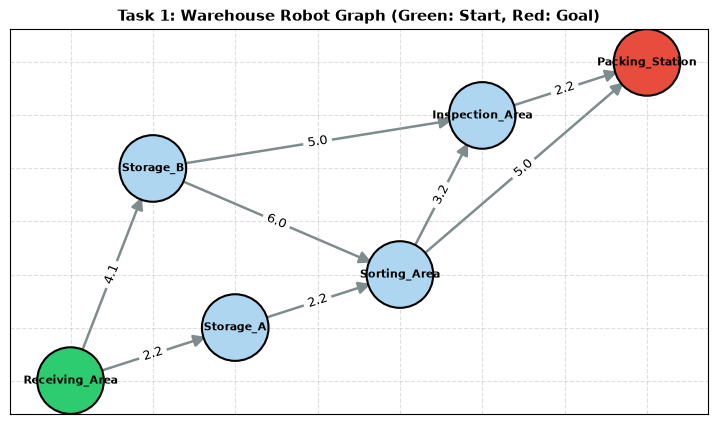

In [1]:
import math
import matplotlib.pyplot as plt
import networkx as nx

# 1. Store coordinates of warehouse locations
locations = {
    "Receiving_Area": (0, 0),
    "Storage_A": (2, 1),
    "Storage_B": (1, 4),
    "Sorting_Area": (4, 2),
    "Inspection_Area": (5, 5),
    "Packing_Station": (7, 6),
}

# 2. Represent warehouse as weighted directed graph
warehouse_graph = {
    "Receiving_Area": {"Storage_A": 2.2, "Storage_B": 4.1},
    "Storage_A": {"Sorting_Area": 2.2},
    "Storage_B": {"Inspection_Area": 5.0, "Sorting_Area": 6.0},
    "Sorting_Area": {"Inspection_Area": 3.2, "Packing_Station": 5.0},
    "Inspection_Area": {"Packing_Station": 2.2},
    "Packing_Station": {},
}

goal_node = "Packing_Station"
start_node = "Receiving_Area"

# 3. Euclidean heuristic function
def heuristic(current, goal=goal_node):
    x1, y1 = locations[current]
    x2, y2 = locations[goal]
    return math.sqrt((x2 - x1) ** 2 + (y2 - y1) ** 2)

# 4. Calculate and display heuristic values
print("=" * 65)
print(f"{'Location':<20} | {'Coordinates':<15} | {'h(n)':<15}")
print("=" * 65)
h_values = {}
for loc, coords in locations.items():
    h_val = heuristic(loc, goal_node)
    h_values[loc] = h_val
    print(f"{loc:<20} | {str(coords):<15} | {h_val:.4f}")
print("=" * 65)

# 5. Verify heuristic condition: h(n) <= cost(n, m) + h(m)
print("\nConsistency Verification: h(n) <= cost(n, m) + h(m)")
print("-" * 75)
print(f"{'Edge (n -> m)':<35} | {'h(n)':<8} | {'cost + h(m)':<15} | {'Consistent?'}")
print("-" * 75)
for u, neighbors in warehouse_graph.items():
    for v, cost in neighbors.items():
        h_u = h_values[u]
        h_v = h_values[v]
        rhs = cost + h_v
        is_consistent = h_u <= (rhs + 1e-2)
        print(f"{u + ' -> ' + v:<35} | {h_u:<8.3f} | {cost:.1f} + {h_v:.3f} = {rhs:<6.3f} | {'True' if is_consistent else 'False'}")
print("-" * 75)

# 6. Color-Coded Graph Visualization
G = nx.DiGraph()
for u, neighbors in warehouse_graph.items():
    for v, weight in neighbors.items():
        G.add_edge(u, v, weight=weight)

plt.figure(figsize=(9, 5))
pos = locations

# Node color mapping: Start=Green, Goal=Red, Others=Light Blue
node_colors = []
for node in G.nodes():
    if node == start_node:
        node_colors.append("#2ECC71")  # Green
    elif node == goal_node:
        node_colors.append("#E74C3C")  # Red
    else:
        node_colors.append("#AED6F1")  # Light Blue

nx.draw_networkx_nodes(G, pos, node_color=node_colors, node_size=2300, edgecolors="black", linewidths=1.5)
nx.draw_networkx_labels(G, pos, font_size=8, font_weight="bold")
nx.draw_networkx_edges(G, pos, edge_color="#7F8C8D", arrows=True, arrowsize=18, min_source_margin=22, min_target_margin=22, width=1.8)
edge_labels = nx.get_edge_attributes(G, "weight")
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=9)
plt.title("Task 1: Warehouse Robot Graph (Green: Start, Red: Goal)", fontsize=11, fontweight="bold")
plt.grid(True, linestyle="--", alpha=0.4)
plt.show()

# Task 2: Greedy Best-First Search for Airport Baggage Handling

Node Expansion Sequence: Baggage_Area -> Checkpoint -> Terminal_Hall -> Departure_Gate
Solution Path          : Baggage_Area -> Checkpoint -> Terminal_Hall -> Departure_Gate
Total Path Cost        : 12.30


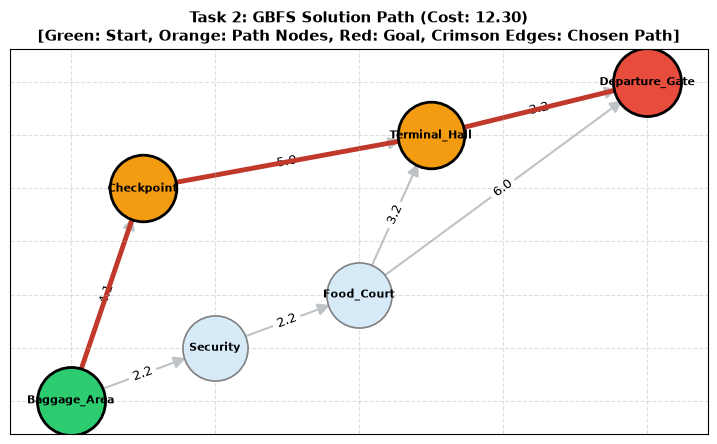

In [2]:
import heapq
import math
import matplotlib.pyplot as plt
import networkx as nx

# 1. Airport layout coordinates and graph
airport_locations = {
    "Baggage_Area": (0, 0),
    "Security": (2, 1),
    "Checkpoint": (1, 4),
    "Food_Court": (4, 2),
    "Terminal_Hall": (5, 5),
    "Departure_Gate": (8, 6),
}

airport_graph = {
    "Baggage_Area": {"Security": 2.2, "Checkpoint": 4.1},
    "Security": {"Food_Court": 2.2},
    "Checkpoint": {"Terminal_Hall": 5.0},
    "Food_Court": {"Terminal_Hall": 3.2, "Departure_Gate": 6.0},
    "Terminal_Hall": {"Departure_Gate": 3.2},
    "Departure_Gate": {},
}

start_node = "Baggage_Area"
goal_node = "Departure_Gate"

def airport_heuristic(node, goal=goal_node):
    x1, y1 = airport_locations[node]
    x2, y2 = airport_locations[goal]
    return math.sqrt((x2 - x1) ** 2 + (y2 - y1) ** 2)

def reconstruct_path(came_from, current):
    path = [current]
    while current in came_from and came_from[current] is not None:
        current = came_from[current]
        path.append(current)
    path.reverse()
    return path

def gbfs(graph, start, goal):
    counter = 0
    frontier = []
    heapq.heappush(frontier, (airport_heuristic(start, goal), counter, start))
    came_from = {start: None}
    visited = set()
    expansion_order = []

    while frontier:
        h_val, _, current = heapq.heappop(frontier)
        if current in visited:
            continue
        visited.add(current)
        expansion_order.append(current)

        if current == goal:
            path = reconstruct_path(came_from, current)
            cost = sum(graph[path[i]][path[i + 1]] for i in range(len(path) - 1))
            return path, cost, expansion_order

        for neighbor in graph[current]:
            if neighbor not in visited and neighbor not in came_from:
                came_from[neighbor] = current
                counter += 1
                heapq.heappush(frontier, (airport_heuristic(neighbor, goal), counter, neighbor))

    return None, float("inf"), expansion_order

path_gbfs, cost_gbfs, exp_gbfs = gbfs(airport_graph, start_node, goal_node)

print("Node Expansion Sequence:", " -> ".join(exp_gbfs))
print("Solution Path          :", " -> ".join(path_gbfs))
print(f"Total Path Cost        : {cost_gbfs:.2f}")

# Color-Coded NetworkX Graph Visualization
G2 = nx.DiGraph()
for u, nbrs in airport_graph.items():
    for v, w in nbrs.items():
        G2.add_edge(u, v, weight=w)

plt.figure(figsize=(9, 5))
pos = airport_locations

# Base graph
nx.draw_networkx_nodes(G2, pos, node_color="#D6EAF8", node_size=2200, edgecolors="gray", linewidths=1.2)
nx.draw_networkx_labels(G2, pos, font_size=8, font_weight="bold")
nx.draw_networkx_edges(G2, pos, edge_color="#BDC3C7", arrows=True, arrowsize=18, min_source_margin=22, min_target_margin=22, width=1.5)
edge_labels = nx.get_edge_attributes(G2, "weight")
nx.draw_networkx_edge_labels(G2, pos, edge_labels=edge_labels, font_size=9)

# Highlighted Path: Start (Green), Path (Orange/Gold), Goal (Red), Path Edges (Crimson)
path_edges = list(zip(path_gbfs, path_gbfs[1:]))
nx.draw_networkx_nodes(G2, pos, nodelist=path_gbfs, node_color="#F39C12", node_size=2300, edgecolors="black", linewidths=2.0)
nx.draw_networkx_nodes(G2, pos, nodelist=[start_node], node_color="#2ECC71", node_size=2400, edgecolors="black", linewidths=2.0)
nx.draw_networkx_nodes(G2, pos, nodelist=[goal_node], node_color="#E74C3C", node_size=2400, edgecolors="black", linewidths=2.0)
nx.draw_networkx_edges(G2, pos, edgelist=path_edges, edge_color="#C0392B", width=3.5, arrows=True, arrowsize=22)

plt.title(f"Task 2: GBFS Solution Path (Cost: {cost_gbfs:.2f})\n[Green: Start, Orange: Path Nodes, Red: Goal, Crimson Edges: Chosen Path]", fontsize=11, fontweight="bold")
plt.grid(True, linestyle="--", alpha=0.4)
plt.show()

# Task 3: A* Search Algorithm for an Emergency Supply Robot

Step   | Node Selected      | g(n)     | h(n)     | f(n) = g + h
1      | Pharmacy           | 0.00     | 10.00    | 10.00       
2      | Main_Corridor      | 2.20     | 7.81     | 10.01       
3      | Nursing_Station    | 4.40     | 5.66     | 10.06       
4      | Emergency_Ward     | 10.40    | 0.00     | 10.40       

Solution Path  : Pharmacy -> Main_Corridor -> Nursing_Station -> Emergency_Ward
Total Path Cost: 10.40


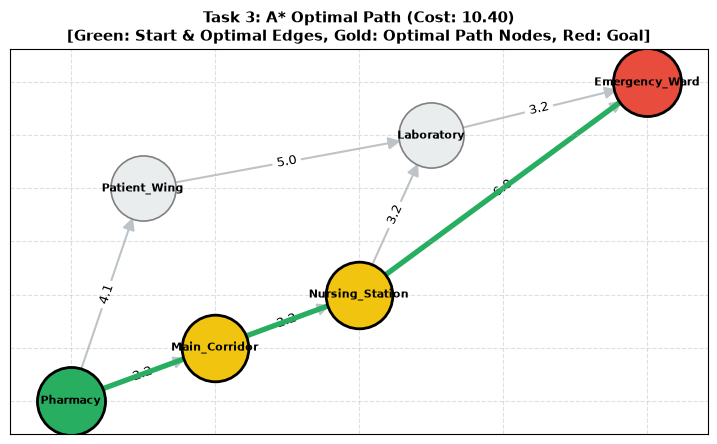

In [3]:
import heapq
import math
import matplotlib.pyplot as plt
import networkx as nx

# 1. Hospital locations and graph
hospital_locations = {
    "Pharmacy": (0, 0),
    "Main_Corridor": (2, 1),
    "Patient_Wing": (1, 4),
    "Nursing_Station": (4, 2),
    "Laboratory": (5, 5),
    "Emergency_Ward": (8, 6),
}

hospital_graph = {
    "Pharmacy": {"Main_Corridor": 2.2, "Patient_Wing": 4.1},
    "Main_Corridor": {"Nursing_Station": 2.2},
    "Patient_Wing": {"Laboratory": 5.0},
    "Nursing_Station": {"Laboratory": 3.2, "Emergency_Ward": 6.0},
    "Laboratory": {"Emergency_Ward": 3.2},
    "Emergency_Ward": {},
}

start_node = "Pharmacy"
goal_node = "Emergency_Ward"

def hospital_heuristic(node, goal=goal_node):
    x1, y1 = hospital_locations[node]
    x2, y2 = hospital_locations[goal]
    return math.sqrt((x2 - x1) ** 2 + (y2 - y1) ** 2)

def reconstruct_path(came_from, current):
    path = [current]
    while current in came_from and came_from[current] is not None:
        current = came_from[current]
        path.append(current)
    path.reverse()
    return path

def a_star(graph, start, goal):
    counter = 0
    frontier = []
    h_start = hospital_heuristic(start, goal)
    heapq.heappush(frontier, (0.0 + h_start, 0.0, counter, start))
    came_from = {start: None}
    g_cost = {start: 0.0}
    visited = set()
    expansion_history = []

    while frontier:
        f, g, _, current = heapq.heappop(frontier)
        if current in visited:
            continue
        visited.add(current)
        h = hospital_heuristic(current, goal)
        expansion_history.append({"node": current, "g": g, "h": h, "f": f})

        if current == goal:
            path = reconstruct_path(came_from, current)
            return path, g_cost[goal], expansion_history

        for neighbor, weight in graph[current].items():
            tentative_g = g_cost[current] + weight
            if tentative_g < g_cost.get(neighbor, float("inf")):
                g_cost[neighbor] = tentative_g
                came_from[neighbor] = current
                h_nbr = hospital_heuristic(neighbor, goal)
                counter += 1
                heapq.heappush(frontier, (tentative_g + h_nbr, tentative_g, counter, neighbor))

    return None, float("inf"), expansion_history

path_astar, cost_astar, history_astar = a_star(hospital_graph, start_node, goal_node)

print("=" * 65)
print(f"{'Step':<6} | {'Node Selected':<18} | {'g(n)':<8} | {'h(n)':<8} | {'f(n) = g + h':<12}")
print("=" * 65)
for idx, step in enumerate(history_astar, 1):
    print(f"{idx:<6} | {step['node']:<18} | {step['g']:<8.2f} | {step['h']:<8.2f} | {step['f']:<12.2f}")
print("=" * 65)

print("\nSolution Path  :", " -> ".join(path_astar))
print(f"Total Path Cost: {cost_astar:.2f}")

# Color-Coded NetworkX Graph: Optimal Path Highlighted in Bright Green & Gold
G3 = nx.DiGraph()
for u, nbrs in hospital_graph.items():
    for v, w in nbrs.items():
        G3.add_edge(u, v, weight=w)

plt.figure(figsize=(9, 5))
pos = hospital_locations

# Base graph
nx.draw_networkx_nodes(G3, pos, node_color="#EAEDED", node_size=2200, edgecolors="gray", linewidths=1.2)
nx.draw_networkx_labels(G3, pos, font_size=8, font_weight="bold")
nx.draw_networkx_edges(G3, pos, edge_color="#BDC3C7", arrows=True, arrowsize=18, min_source_margin=22, min_target_margin=22, width=1.5)
edge_labels = nx.get_edge_attributes(G3, "weight")
nx.draw_networkx_edge_labels(G3, pos, edge_labels=edge_labels, font_size=9)

# Highlight Optimal Path
path_edges3 = list(zip(path_astar, path_astar[1:]))
nx.draw_networkx_nodes(G3, pos, nodelist=path_astar, node_color="#F1C40F", node_size=2300, edgecolors="black", linewidths=2.0)
nx.draw_networkx_nodes(G3, pos, nodelist=[start_node], node_color="#27AE60", node_size=2400, edgecolors="black", linewidths=2.0)
nx.draw_networkx_nodes(G3, pos, nodelist=[goal_node], node_color="#E74C3C", node_size=2400, edgecolors="black", linewidths=2.0)
nx.draw_networkx_edges(G3, pos, edgelist=path_edges3, edge_color="#27AE60", width=3.8, arrows=True, arrowsize=22)

plt.title(f"Task 3: A* Optimal Path (Cost: {cost_astar:.2f})\n[Green: Start & Optimal Edges, Gold: Optimal Path Nodes, Red: Goal]", fontsize=11, fontweight="bold")
plt.grid(True, linestyle="--", alpha=0.4)
plt.show()

# Task 4: Weighted A* for an Autonomous Delivery Drone

Weight w   | Solution Path                                 | Total Cost   | Nodes Expanded 
1.0        | Distribution_Center -> Zone_A -> Zone_C -> Customer_Building | 10.40        | 5              
1.5        | Distribution_Center -> Zone_A -> Zone_C -> Customer_Building | 10.40        | 4              
2.0        | Distribution_Center -> Zone_B -> Zone_D -> Customer_Building | 11.20        | 4              
3.0        | Distribution_Center -> Zone_B -> Zone_D -> Customer_Building | 11.20        | 4              


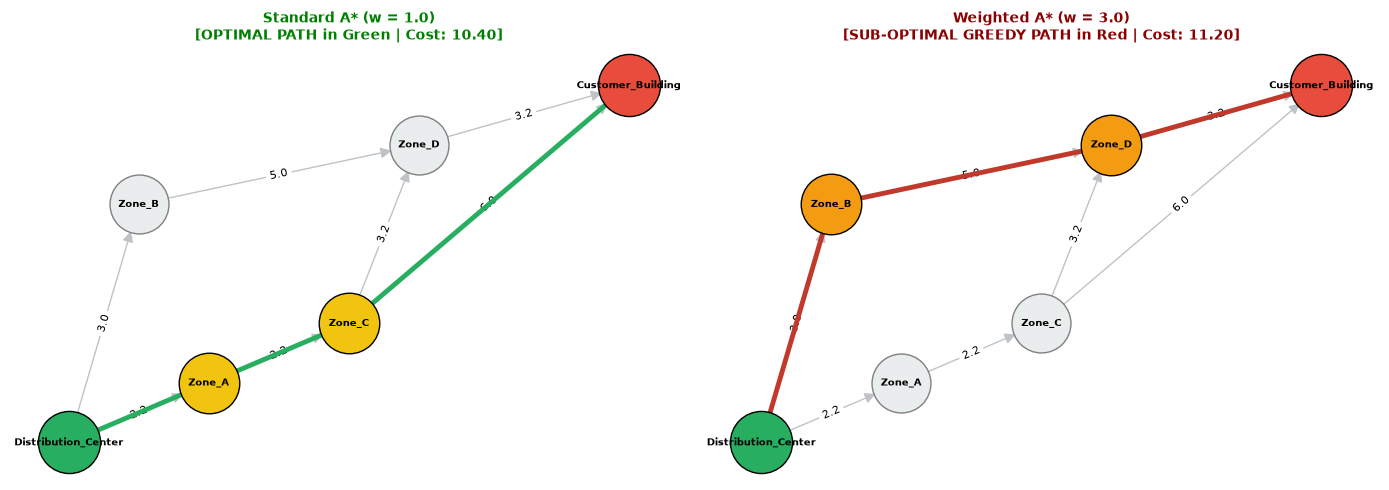

In [4]:
import heapq
import math
import matplotlib.pyplot as plt
import networkx as nx

drone_locations = {
    "Distribution_Center": (0, 0),
    "Zone_A": (2, 1),
    "Zone_B": (1, 4),
    "Zone_C": (4, 2),
    "Zone_D": (5, 5),
    "Customer_Building": (8, 6),
}

drone_graph = {
    "Distribution_Center": {"Zone_A": 2.2, "Zone_B": 3.0},
    "Zone_A": {"Zone_C": 2.2},
    "Zone_B": {"Zone_D": 5.0},
    "Zone_C": {"Zone_D": 3.2, "Customer_Building": 6.0},
    "Zone_D": {"Customer_Building": 3.2},
    "Customer_Building": {},
}

start_node = "Distribution_Center"
goal_node = "Customer_Building"

def drone_heuristic(node, goal=goal_node):
    x1, y1 = drone_locations[node]
    x2, y2 = drone_locations[goal]
    return math.sqrt((x2 - x1) ** 2 + (y2 - y1) ** 2)

def reconstruct_path(came_from, current):
    path = [current]
    while current in came_from and came_from[current] is not None:
        current = came_from[current]
        path.append(current)
    path.reverse()
    return path

def weighted_a_star(graph, start, goal, w=1.0):
    counter = 0
    frontier = []
    h_start = drone_heuristic(start, goal)
    heapq.heappush(frontier, (0.0 + w * h_start, 0.0, counter, start))
    came_from = {start: None}
    g_cost = {start: 0.0}
    visited = set()
    expansion_order = []

    while frontier:
        f, g, _, current = heapq.heappop(frontier)
        if current in visited:
            continue
        visited.add(current)
        expansion_order.append(current)

        if current == goal:
            path = reconstruct_path(came_from, current)
            return path, g_cost[goal], len(expansion_order)

        for neighbor, weight in graph[current].items():
            tentative_g = g_cost[current] + weight
            if tentative_g < g_cost.get(neighbor, float("inf")):
                g_cost[neighbor] = tentative_g
                came_from[neighbor] = current
                f_nbr = tentative_g + w * drone_heuristic(neighbor, goal)
                counter += 1
                heapq.heappush(frontier, (f_nbr, tentative_g, counter, neighbor))

    return None, float("inf"), len(expansion_order)

weights = [1.0, 1.5, 2.0, 3.0]
print("=" * 85)
print(f"{'Weight w':<10} | {'Solution Path':<45} | {'Total Cost':<12} | {'Nodes Expanded':<15}")
print("=" * 85)
for w in weights:
    path, cost, num_exp = weighted_a_star(drone_graph, start_node, goal_node, w=w)
    print(f"{w:<10} | {' -> '.join(path):<45} | {cost:<12.2f} | {num_exp:<15}")
print("=" * 85)

# Color-Coded Comparison Plot: Optimal Path (Green) vs Sub-optimal Path (Red)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
G4 = nx.DiGraph()
for u, nbrs in drone_graph.items():
    for v, w in nbrs.items():
        G4.add_edge(u, v, weight=w)
pos4 = drone_locations
edge_labels4 = nx.get_edge_attributes(G4, "weight")

# Subplot 1: w = 1.0 (Optimal Path in Green)
ax1 = axes[0]
path_w1 = ['Distribution_Center', 'Zone_A', 'Zone_C', 'Customer_Building']
nx.draw_networkx_nodes(G4, pos4, ax=ax1, node_color="#EAEDED", node_size=1800, edgecolors="gray")
nx.draw_networkx_labels(G4, pos4, ax=ax1, font_size=7, font_weight="bold")
nx.draw_networkx_edges(G4, pos4, ax=ax1, edge_color="#BDC3C7", arrows=True, arrowsize=16, min_source_margin=20, min_target_margin=20)
nx.draw_networkx_edge_labels(G4, pos4, edge_labels=edge_labels4, font_size=8, ax=ax1)
p_edges_w1 = list(zip(path_w1, path_w1[1:]))
nx.draw_networkx_nodes(G4, pos4, nodelist=path_w1, node_color="#F1C40F", node_size=1900, edgecolors="black", ax=ax1)
nx.draw_networkx_nodes(G4, pos4, nodelist=[start_node], node_color="#27AE60", node_size=2000, edgecolors="black", ax=ax1)
nx.draw_networkx_nodes(G4, pos4, nodelist=[goal_node], node_color="#E74C3C", node_size=2000, edgecolors="black", ax=ax1)
nx.draw_networkx_edges(G4, pos4, edgelist=p_edges_w1, edge_color="#27AE60", width=3.5, arrows=True, arrowsize=18, ax=ax1)
ax1.set_title("Standard A* (w = 1.0)\n[OPTIMAL PATH in Green | Cost: 10.40]", fontsize=10, fontweight="bold", color="green")
ax1.axis("off")

# Subplot 2: w = 3.0 (Sub-optimal Greedy Path in Red)
ax2 = axes[1]
path_w3 = ['Distribution_Center', 'Zone_B', 'Zone_D', 'Customer_Building']
nx.draw_networkx_nodes(G4, pos4, ax=ax2, node_color="#EAEDED", node_size=1800, edgecolors="gray")
nx.draw_networkx_labels(G4, pos4, ax=ax2, font_size=7, font_weight="bold")
nx.draw_networkx_edges(G4, pos4, ax=ax2, edge_color="#BDC3C7", arrows=True, arrowsize=16, min_source_margin=20, min_target_margin=20)
nx.draw_networkx_edge_labels(G4, pos4, edge_labels=edge_labels4, font_size=8, ax=ax2)
p_edges_w3 = list(zip(path_w3, path_w3[1:]))
nx.draw_networkx_nodes(G4, pos4, nodelist=path_w3, node_color="#F39C12", node_size=1900, edgecolors="black", ax=ax2)
nx.draw_networkx_nodes(G4, pos4, nodelist=[start_node], node_color="#27AE60", node_size=2000, edgecolors="black", ax=ax2)
nx.draw_networkx_nodes(G4, pos4, nodelist=[goal_node], node_color="#E74C3C", node_size=2000, edgecolors="black", ax=ax2)
nx.draw_networkx_edges(G4, pos4, edgelist=p_edges_w3, edge_color="#C0392B", width=3.5, arrows=True, arrowsize=18, ax=ax2)
ax2.set_title("Weighted A* (w = 3.0)\n[SUB-OPTIMAL GREEDY PATH in Red | Cost: 11.20]", fontsize=10, fontweight="bold", color="darkred")
ax2.axis("off")

plt.tight_layout()
plt.show()

# Task 5: Finding a Charging Station Using Multiple Goals

Measure                        | GBFS                 | A*                  
Charging station reached       | Charging_Central     | Charging_Central    
Solution path                  | Current_Location -> Junction_A -> Junction_C -> Charging_Central | Current_Location -> Junction_A -> Junction_C -> Charging_Central
Total path cost                | 8.40                 | 8.40                
Number of nodes expanded       | 4                    | 4                   


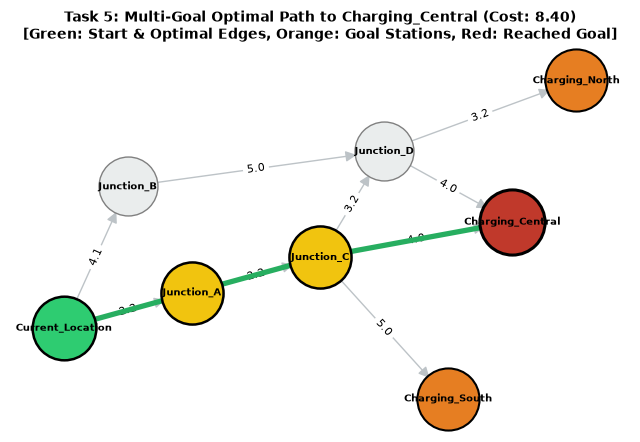

In [5]:
import heapq
import math
import matplotlib.pyplot as plt
import networkx as nx

charging_locations = {
    "Current_Location": (0, 0),
    "Junction_A": (2, 1),
    "Junction_B": (1, 4),
    "Junction_C": (4, 2),
    "Junction_D": (5, 5),
    "Charging_North": (8, 7),
    "Charging_Central": (7, 3),
    "Charging_South": (6, -2),
}

charging_graph = {
    "Current_Location": {"Junction_A": 2.2, "Junction_B": 4.1},
    "Junction_A": {"Junction_C": 2.2},
    "Junction_B": {"Junction_D": 5.0},
    "Junction_C": {"Junction_D": 3.2, "Charging_Central": 4.0, "Charging_South": 5.0},
    "Junction_D": {"Charging_North": 3.2, "Charging_Central": 4.0},
    "Charging_North": {},
    "Charging_Central": {},
    "Charging_South": {},
}

goal_stations = {"Charging_North", "Charging_Central", "Charging_South"}
start_node = "Current_Location"

def multi_goal_heuristic(node):
    x1, y1 = charging_locations[node]
    return min(math.sqrt((charging_locations[g][0] - x1) ** 2 + (charging_locations[g][1] - y1) ** 2) for g in goal_stations)

def reconstruct_path(came_from, current):
    path = [current]
    while current in came_from and came_from[current] is not None:
        current = came_from[current]
        path.append(current)
    path.reverse()
    return path

def gbfs_multi(graph, start, goals):
    counter = 0
    frontier = []
    heapq.heappush(frontier, (multi_goal_heuristic(start), counter, start))
    came_from = {start: None}
    visited = set()
    expansion_order = []

    while frontier:
        h, _, current = heapq.heappop(frontier)
        if current in visited:
            continue
        visited.add(current)
        expansion_order.append(current)

        if current in goals:
            path = reconstruct_path(came_from, current)
            cost = sum(graph[path[i]][path[i + 1]] for i in range(len(path) - 1))
            return path, cost, current, expansion_order

        for nbr in graph[current]:
            if nbr not in visited and nbr not in came_from:
                came_from[nbr] = current
                counter += 1
                heapq.heappush(frontier, (multi_goal_heuristic(nbr), counter, nbr))
    return None, float("inf"), None, expansion_order

def astar_multi(graph, start, goals):
    counter = 0
    frontier = []
    h_start = multi_goal_heuristic(start)
    heapq.heappush(frontier, (0.0 + h_start, 0.0, counter, start))
    came_from = {start: None}
    g_cost = {start: 0.0}
    visited = set()
    expansion_order = []

    while frontier:
        f, g, _, current = heapq.heappop(frontier)
        if current in visited:
            continue
        visited.add(current)
        expansion_order.append(current)

        if current in goals:
            path = reconstruct_path(came_from, current)
            return path, g_cost[current], current, expansion_order

        for nbr, weight in graph[current].items():
            tentative_g = g_cost[current] + weight
            if tentative_g < g_cost.get(nbr, float("inf")):
                g_cost[nbr] = tentative_g
                came_from[nbr] = current
                f_nbr = tentative_g + multi_goal_heuristic(nbr)
                counter += 1
                heapq.heappush(frontier, (f_nbr, tentative_g, counter, nbr))
    return None, float("inf"), None, expansion_order

path_mg_gbfs, cost_mg_gbfs, goal_mg_gbfs, exp_mg_gbfs = gbfs_multi(charging_graph, start_node, goal_stations)
path_mg_astar, cost_mg_astar, goal_mg_astar, exp_mg_astar = astar_multi(charging_graph, start_node, goal_stations)

print("=" * 75)
print(f"{'Measure':<30} | {'GBFS':<20} | {'A*':<20}")
print("=" * 75)
print(f"{'Charging station reached':<30} | {goal_mg_gbfs:<20} | {goal_mg_astar:<20}")
print(f"{'Solution path':<30} | {' -> '.join(path_mg_gbfs):<20} | {' -> '.join(path_mg_astar):<20}")
print(f"{'Total path cost':<30} | {cost_mg_gbfs:<20.2f} | {cost_mg_astar:<20.2f}")
print(f"{'Number of nodes expanded':<30} | {len(exp_mg_gbfs):<20} | {len(exp_mg_astar):<20}")
print("=" * 75)

# Color-Coded Multi-Goal Network Visualization
fig, ax = plt.subplots(figsize=(8, 5))
G5 = nx.DiGraph()
for u, nbrs in charging_graph.items():
    for v, w in nbrs.items():
        G5.add_edge(u, v, weight=w)

pos = charging_locations
# Base nodes
nx.draw_networkx_nodes(G5, pos, ax=ax, node_color="#EAEDED", node_size=1800, edgecolors="gray")
nx.draw_networkx_labels(G5, pos, ax=ax, font_size=7, font_weight="bold")
nx.draw_networkx_edges(G5, pos, ax=ax, edge_color="#BDC3C7", arrows=True, arrowsize=16, min_source_margin=20, min_target_margin=20)
edge_labels = nx.get_edge_attributes(G5, "weight")
nx.draw_networkx_edge_labels(G5, pos, edge_labels=edge_labels, font_size=8)

# Highlight all charging stations in Orange
nx.draw_networkx_nodes(G5, pos, nodelist=list(goal_stations), node_color="#E67E22", node_size=2000, edgecolors="black", linewidths=1.5, ax=ax)
# Highlight Start in Green
nx.draw_networkx_nodes(G5, pos, nodelist=[start_node], node_color="#2ECC71", node_size=2100, edgecolors="black", linewidths=1.8, ax=ax)
# Highlight Optimal Path Nodes in Gold
p_edges = list(zip(path_mg_astar, path_mg_astar[1:]))
nx.draw_networkx_nodes(G5, pos, nodelist=path_mg_astar[1:-1], node_color="#F1C40F", node_size=2000, edgecolors="black", linewidths=1.8, ax=ax)
# Highlight Reached Goal in Dark Red
nx.draw_networkx_nodes(G5, pos, nodelist=[goal_mg_astar], node_color="#C0392B", node_size=2200, edgecolors="black", linewidths=2.2, ax=ax)
# Highlight Optimal Path Edges in Green
nx.draw_networkx_edges(G5, pos, edgelist=p_edges, edge_color="#27AE60", width=3.8, arrows=True, arrowsize=18, ax=ax)

ax.set_title(f"Task 5: Multi-Goal Optimal Path to {goal_mg_astar} (Cost: {cost_mg_astar:.2f})\n[Green: Start & Optimal Edges, Orange: Goal Stations, Red: Reached Goal]", fontsize=10, fontweight="bold")
ax.axis("off")
plt.show()